# Week 7-C2: Utility-Aware Budget Ranking and Continuation Policy

## 1. Why W7-C1 Failed: The Non-Monotonicity and Fallback Trap

In **Week 7-C1**, we attempted to formulate representation budget selection as candidate-level binary sufficiency classification:
$$P(z(q,k)=1) \ge 	au, \quad 	ext{fallback: } k=8$$

This produced a disappointing DEV result:
- **$F_1 = 0.3783$** at mean $k = 6.85$ and context $\approx 1503.8$ tokens.
- Heavily dominated by static semantic $k=4$ ($F_1 = 0.3909$, tokens $\approx 921.1$).

### The Two Root Causes of W7-C1's Failure:
1. **The Fallback-to-$k8$ Assumption:**
   Because sufficiency ($r \le 0.01$) was difficult to establish with high confidence at small budgets, and the calibrated threshold was high ($\tau = 0.80 - 0.90$), the policy triggered fallback to $k=8$ for $74\% - 90\%$ of queries.
2. **The Non-Monotonicity Trap:**
   The fallback assumed that larger budgets are inherently "safer". In reality, the SARA response surface is **non-monotonic**:
   $$F(q,8) \not\ge F(q,6) \not\ge F(q,4)$$
   Extraneous passages at $k=8$ introduce distractors that actively degrade downstream generation accuracy for many queries. Falling back to $k=8$ destroyed performance on queries where $k=4$ was optimal.

---

## 2. The W7-C2 Paradigm Shift

Instead of classifying candidate budgets independently as sufficient/insufficient with a dangerous large-$k$ fallback, **W7-C2 learns the relative downstream utility across candidate representation budgets directly**:
$$\boxed{(q, D_{1:10}, k) \longrightarrow \text{direct quality utility } \hat{F}(q,k) \quad\text{or comparative rank score } s(q,k)}$$

We implement three complementary formulations:
- **M1: Direct Response-Surface Regression** predicting $\hat{F}(q,k) \approx F(q,k)$ with cost-aware near-tie selection:
  $$\hat{k} = \arg\min_{k \in \hat{\mathcal{A}}_\delta} \text{Tokens}(q,k) \quad\text{where } \hat{\mathcal{A}}_\delta = \{k : \hat{F}(q,k) \ge \max_j \hat{F}(q,j) - \delta\}$$
- **M2: Query-Grouped Learning-to-Rank (PRIMARY)** training a pairwise/listwise ranker over the 5 candidate actions per query using lexicographic quality-cost relevance grades.
- **M3: Stagewise Continuation Policy (Secondary)** evaluating whether future budgets provide meaningful marginal gains: $y_{\text{continue}} = \mathbf{1}[\max_{j>k} F(q,j) - F(q,k) > 0.01]$.


## Section 1: Setup, Environment, and Reproducibility


In [1]:
import os
import sys
import json
import time
import yaml
from pathlib import Path
from typing import Dict, List, Any, Tuple

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Resolve Project Root across execution environments
_curr = Path.cwd().resolve()
candidates = [_curr, _curr.parent, _curr.parent.parent]
PROJECT_ROOT = next((p for p in candidates if (p / "src").is_dir() and (p / "configs").is_dir()), _curr)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

SARA_ROOT = PROJECT_ROOT / "Baselines/SARA-main"
if str(SARA_ROOT) not in sys.path:
    sys.path.append(str(SARA_ROOT))

# Load Week 7-C2 Configuration
CONFIG_PATH = PROJECT_ROOT / "configs/week7/w7c2_utility_aware_budget_ranking.yaml"
with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

# Set random seeds
SEED = cfg.get("seed", 42)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BUDGETS = cfg.get("budgets", [2, 4, 5, 6, 8])
EPSILON = cfg.get("epsilon", 0.01)
EPS_PREF = cfg.get("preference_epsilon", 0.01)

# Ensure output directories exist
for p_key in ["models_dir", "tables_dir", "figures_dir", "bootstrap_dir", "diagnostics_dir", "smoke_dir", "logs_dir"]:
    Path(cfg["paths"][p_key]).mkdir(parents=True, exist_ok=True)

print(f"Project Root: {PROJECT_ROOT}")
print(f"Device: {DEVICE} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")
print(f"Budgets: {BUDGETS}, Epsilon: {EPSILON}, Preference Epsilon: {EPS_PREF}")


Project Root: /home/gunavenkat/Downloads/CS787-RAG-Project
Device: cuda (NVIDIA TITAN RTX)
Budgets: [2, 4, 5, 6, 8], Epsilon: 0.01, Preference Epsilon: 0.01


## Section 2: Split Integrity & TEST Split Inaccessibility Guard


In [2]:
from src.week7.w7c2.data import assert_test_disabled, load_w7c2_splits
from src.week7.w7c.data import load_w7c_dataset_bundle

# 1. Assert TEST split is strictly disabled
try:
    assert_test_disabled("test")
except RuntimeError as e:
    print(f"PASS: TEST split access guard strictly validated: {e}")

# 2. Load TRAIN-FIT and INTERNAL-VAL split manifests
df_fit_manifest, df_val_manifest = load_w7c2_splits(
    train_fit_manifest_path=cfg["paths"]["train_fit_manifest"],
    internal_val_manifest_path=cfg["paths"]["internal_val_manifest"],
)
print(f"TRAIN-FIT:     {len(df_fit_manifest)} queries ({df_fit_manifest['paper_id'].nunique()} papers)")
print(f"INTERNAL-VAL:  {len(df_val_manifest)} queries ({df_val_manifest['paper_id'].nunique()} papers)")

# 3. Load retrieval bundle metadata
dev_bundle = load_w7c_dataset_bundle(cfg["paths"]["dev_retrieval"], split="dev")
print(f"DEV:           {dev_bundle['n_queries']} queries ({dev_bundle['n_papers']} papers)")


PASS: TEST split access guard strictly validated: TEST split access is strictly prohibited in Week 7-C2! TEST must remain untouched.
TRAIN-FIT:     1746 queries (656 papers)
INTERNAL-VAL:  342 queries (116 papers)
DEV:           231 queries (86 papers)


/home/gunavenkat/Downloads/CS787-RAG-Project/sara_env/lib/python3.11/site-packages/xgboost/core.py:377: FutureWarning: Your system has an old version of glibc (< 2.28). We will stop supporting Linux distros with glibc older than 2.28 after **May 31, 2025**. Please upgrade to a recent Linux distro (with glibc >= 2.28) to use future versions of XGBoost.
Note: You have installed the 'manylinux2014' variant of XGBoost. Certain features such as GPU algorithms or federated learning are not available. To use these features, please upgrade to a recent Linux distro with glibc 2.28+, and install the 'manylinux_2_28' variant.
  warnings.warn(


## Section 3: Load Canonical Artifacts (W7-B Response Surface & W7-C1 Feature Bank)


In [3]:
# 1. Load canonical W7-B semantic response surfaces
df_train_matrix = pd.read_csv(cfg["paths"]["train_semantic_matrix"])
df_train_matrix["question_id"] = df_train_matrix["question_id"].astype(str).str.strip()
df_train_matrix["paper_id"] = df_train_matrix["paper_id"].astype(str).str.strip()

df_dev_matrix = pd.read_csv(cfg["paths"]["dev_semantic_matrix"])
df_dev_matrix["question_id"] = df_dev_matrix["question_id"].astype(str).str.strip()
df_dev_matrix["paper_id"] = df_dev_matrix["paper_id"].astype(str).str.strip()

print(f"Loaded TRAIN response matrix: {df_train_matrix.shape} (2088 queries x 5 budgets)")
print(f"Loaded DEV response matrix:   {df_dev_matrix.shape} (231 queries x 5 budgets)")

# 2. Load W7-C1 feature banks directly from parquet
print("\nLoading precomputed candidate feature banks from W7-C1...")
df_train_feats = pd.read_parquet(cfg["paths"]["train_candidate_features"])
df_train_feats["question_id"] = df_train_feats["question_id"].astype(str).str.strip()
df_train_feats["paper_id"] = df_train_feats["paper_id"].astype(str).str.strip()

df_dev_feats = pd.read_parquet(cfg["paths"]["dev_candidate_features"])
df_dev_feats["question_id"] = df_dev_feats["question_id"].astype(str).str.strip()
df_dev_feats["paper_id"] = df_dev_feats["paper_id"].astype(str).str.strip()

print(f"  TRAIN candidate features: {df_train_feats.shape}")
print(f"  DEV candidate features:   {df_dev_feats.shape}")


Loaded TRAIN response matrix: (2088, 12) (2088 queries x 5 budgets)
Loaded DEV response matrix:   (231, 12) (231 queries x 5 budgets)

Loading precomputed candidate feature banks from W7-C1...
  TRAIN candidate features: (10440, 115)
  DEV candidate features:   (1155, 115)


## Section 4: W7-C1 Model and Feature Selection Audit


In [4]:
# Display the W7-C1 selection audit findings
audit_file = PROJECT_ROOT / "results/week7/w7c2_utility_ranking/diagnostics/w7c1_selection_audit.md"
if audit_file.exists():
    with open(audit_file, "r") as f:
        print(f.read())
else:
    print("Audit file not found.")


# W7-C1 Model and Feature Selection Audit

**Date:** 2026-10-15  
**Artifact:** `results/week7/w7c2_utility_ranking/diagnostics/w7c1_selection_audit.md`  
**Purpose:** Investigate the failure modes of W7-C1 and audit why feature set F4 was reported as the winner despite INTERNAL-VAL metrics.

---

## 1. Canonical INTERNAL-VAL Feature Ablation Metrics (W7-C1)

From `results/week7/w7c_retrieval_aware_allocator/tables/w7c_feature_ablation_internal_val.csv`:

| Ablation | Description | Features | Calibrated $\tau$ | Val Downstream $F_1$ | Val Tokens | Val Mean $k$ | Over-Allocation Rate |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **F0** | Old W4 baseline | 6 | 0.90 | **0.438401** | 1756.1 | 8.00 | 90.06% |
| **F1** | Query + Retrieval Geometry | 57 | 0.90 | 0.435477 | 1664.5 | 7.57 | 87.13% |
| **F2** | Retrieval-Aware | 70 | 0.90 | 0.435477 | 1655.8 | 7.53 | 85.09% |
| **F3** | Set-Aware | 79 | 0.90 | 0.432553 | 1647.5 | 7.48 | 84.80% |
| **F4** | Full Sufficiency 

## Section 5: Oracle Stability & Learnability Diagnostics (D1 Margins & D2 Admissible Sets)


D1: Best-vs-Second-Best Quality Margin Summary:


,split,mean_margin,median_margin,p25_margin,p75_margin,frac_below_001,frac_below_002,frac_below_005
0,TRAIN,0.068893,0.0,0.0,0.009643,0.750000,0.762931,0.798372
1,DEV,0.051477,0.0,0.0,0.005775,0.753247,0.766234,0.813853



D2: Epsilon-Admissible Set Size Distribution:


,admissible_set_size,query_count,pct_queries,split
0,1,521,24.952107,TRAIN
1,2,198,9.482759,TRAIN
2,3,156,7.471264,TRAIN
3,4,224,10.727969,TRAIN
4,5,989,47.365900,TRAIN
5,1,57,24.675325,DEV
6,2,22,9.523810,DEV
7,3,26,11.255411,DEV
8,4,18,7.792208,DEV
9,5,108,46.753247,DEV


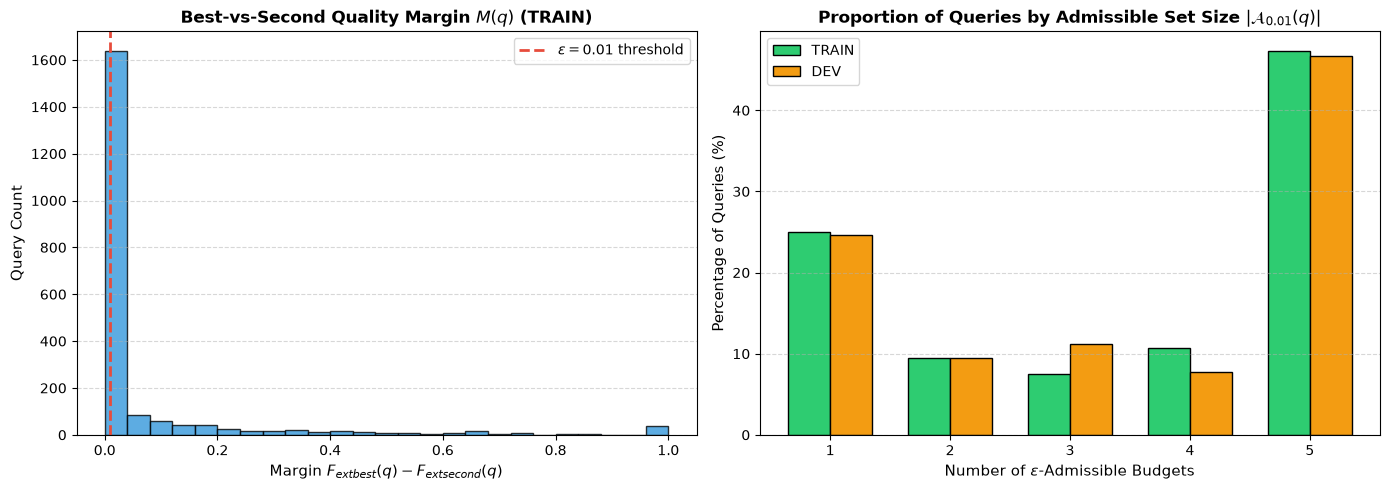

In [5]:
from src.week7.w7c2.diagnostics import compute_best_vs_second_margin, compute_admissible_set_distribution

# D1: Best-vs-Second-Best Quality Margin on TRAIN
margins_train, margin_summary_train = compute_best_vs_second_margin(df_train_matrix, budgets=BUDGETS)
margins_dev, margin_summary_dev = compute_best_vs_second_margin(df_dev_matrix, budgets=BUDGETS)

df_margins_summary = pd.DataFrame([
    {"split": "TRAIN", **margin_summary_train},
    {"split": "DEV", **margin_summary_dev},
])
df_margins_summary.to_csv(Path(cfg["paths"]["tables_dir"]) / "w7c2_oracle_stability_diagnostics.csv", index=False)
print("D1: Best-vs-Second-Best Quality Margin Summary:")
display(df_margins_summary)

# D2: Epsilon-Admissible Set Size Distribution |A_0.01(q)|
sizes_train, df_adm_train = compute_admissible_set_distribution(df_train_matrix, budgets=BUDGETS, epsilon=EPSILON)
sizes_dev, df_adm_dev = compute_admissible_set_distribution(df_dev_matrix, budgets=BUDGETS, epsilon=EPSILON)

df_adm_train["split"] = "TRAIN"
df_adm_dev["split"] = "DEV"
df_adm_combined = pd.concat([df_adm_train, df_adm_dev], ignore_index=True)
df_adm_combined.to_csv(Path(cfg["paths"]["tables_dir"]) / "w7c2_admissible_set_distribution.csv", index=False)
print("\nD2: Epsilon-Admissible Set Size Distribution:")
display(df_adm_combined)

# Plot Margins and Admissible Set Sizes
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Margin Distribution
axes[0].hist(margins_train, bins=25, color="#3498db", edgecolor="black", alpha=0.8)
axes[0].axvline(0.01, color="#e74c3c", linestyle="--", linewidth=2, label="$\epsilon=0.01$ threshold")
axes[0].set_title("Best-vs-Second Quality Margin $M(q)$ (TRAIN)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Margin $F_{\text{best}}(q) - F_{\text{second}}(q)$", fontsize=11)
axes[0].set_ylabel("Query Count", fontsize=11)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
axes[0].legend(frameon=True)

# Plot 2: Admissible Set Size Bar Chart
bar_width = 0.35
indices = np.arange(1, len(BUDGETS) + 1)
axes[1].bar(indices - bar_width/2, df_adm_train["pct_queries"], width=bar_width, color="#2ecc71", edgecolor="black", label="TRAIN")
axes[1].bar(indices + bar_width/2, df_adm_dev["pct_queries"], width=bar_width, color="#f39c12", edgecolor="black", label="DEV")
axes[1].set_title("Proportion of Queries by Admissible Set Size $|\mathcal{A}_{0.01}(q)|$", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Number of $\epsilon$-Admissible Budgets", fontsize=11)
axes[1].set_ylabel("Percentage of Queries (%)", fontsize=11)
axes[1].set_xticks(indices)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)
axes[1].legend(frameon=True)

plt.tight_layout()
plt.savefig(Path(cfg["paths"]["figures_dir"]) / "w7c2_best_vs_second_margin.png", dpi=300)
plt.show()


## Section 6: Non-Monotonicity & Step Reversal Analysis (D3 & D4)


D3: Monotonicity Analysis and Step Reversals:


,split,total_queries,monotonic_pct,non_monotonic_pct,reversals_F4_lt_F2,reversals_F5_lt_F4,reversals_F6_lt_F5,reversals_F8_lt_F6
0,TRAIN,2088,65.229885,34.770115,285,207,190,258
1,DEV,231,62.770563,37.229437,35,32,25,26



D4: Adjacent Marginal Quality Gains:


,step,mean_gain,median_gain,positive_frac,negative_frac,zero_frac,gain_gt_001_frac,drop_lt_minus001_frac,split
0,Delta_2_to_4,0.053810,0.0,0.242816,0.136494,0.620690,0.236590,0.129310,TRAIN
1,Delta_4_to_5,0.011503,0.0,0.135536,0.099138,0.765326,0.128352,0.093391,TRAIN
2,Delta_5_to_6,0.011864,0.0,0.124042,0.090996,0.784962,0.117337,0.083333,TRAIN
3,Delta_6_to_8,0.019723,0.0,0.140326,0.123563,0.736111,0.133621,0.115421,TRAIN
4,Delta_2_to_4,0.079110,0.0,0.242424,0.151515,0.606061,0.233766,0.147186,DEV
5,Delta_4_to_5,0.002172,0.0,0.108225,0.138528,0.753247,0.103896,0.125541,DEV
6,Delta_5_to_6,0.002630,0.0,0.095238,0.108225,0.796537,0.095238,0.099567,DEV
7,Delta_6_to_8,0.005311,0.0,0.129870,0.112554,0.757576,0.125541,0.108225,DEV


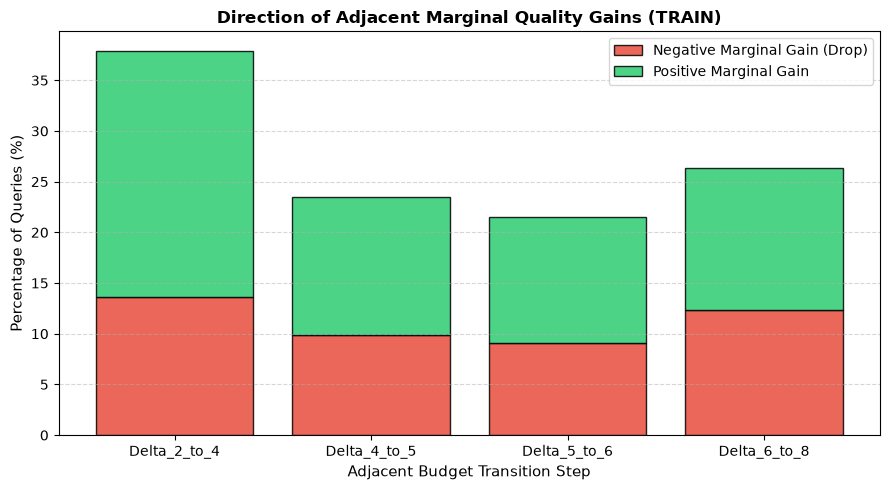

In [6]:
from src.week7.w7c2.diagnostics import compute_monotonicity_analysis, compute_adjacent_marginal_gains

# D3: Monotonicity Analysis
mono_train = compute_monotonicity_analysis(df_train_matrix, budgets=BUDGETS)
mono_dev = compute_monotonicity_analysis(df_dev_matrix, budgets=BUDGETS)

df_mono = pd.DataFrame([
    {
        "split": "TRAIN",
        "total_queries": mono_train["total_queries"],
        "monotonic_pct": mono_train["monotonic_pct"],
        "non_monotonic_pct": mono_train["non_monotonic_pct"],
        "reversals_F4_lt_F2": mono_train["reversals"]["F4_lt_F2"],
        "reversals_F5_lt_F4": mono_train["reversals"]["F5_lt_F4"],
        "reversals_F6_lt_F5": mono_train["reversals"]["F6_lt_F5"],
        "reversals_F8_lt_F6": mono_train["reversals"]["F8_lt_F6"],
    },
    {
        "split": "DEV",
        "total_queries": mono_dev["total_queries"],
        "monotonic_pct": mono_dev["monotonic_pct"],
        "non_monotonic_pct": mono_dev["non_monotonic_pct"],
        "reversals_F4_lt_F2": mono_dev["reversals"]["F4_lt_F2"],
        "reversals_F5_lt_F4": mono_dev["reversals"]["F5_lt_F4"],
        "reversals_F6_lt_F5": mono_dev["reversals"]["F6_lt_F5"],
        "reversals_F8_lt_F6": mono_dev["reversals"]["F8_lt_F6"],
    },
])
df_mono.to_csv(Path(cfg["paths"]["tables_dir"]) / "w7c2_monotonicity_analysis.csv", index=False)
print("D3: Monotonicity Analysis and Step Reversals:")
display(df_mono)

# D4: Adjacent Marginal Gains
df_gains_train = compute_adjacent_marginal_gains(df_train_matrix)
df_gains_train["split"] = "TRAIN"
df_gains_dev = compute_adjacent_marginal_gains(df_dev_matrix)
df_gains_dev["split"] = "DEV"

df_gains_combined = pd.concat([df_gains_train, df_gains_dev], ignore_index=True)
df_gains_combined.to_csv(Path(cfg["paths"]["tables_dir"]) / "w7c2_adjacent_gain_analysis.csv", index=False)
print("\nD4: Adjacent Marginal Quality Gains:")
display(df_gains_combined)

# Plot Adjacent Gains Distributions
plt.figure(figsize=(9, 5))
steps = df_gains_train["step"].values
plt.bar(steps, df_gains_train["negative_frac"] * 100, color="#e74c3c", alpha=0.85, edgecolor="black", label="Negative Marginal Gain (Drop)")
plt.bar(steps, df_gains_train["positive_frac"] * 100, bottom=df_gains_train["negative_frac"] * 100, color="#2ecc71", alpha=0.85, edgecolor="black", label="Positive Marginal Gain")
plt.title("Direction of Adjacent Marginal Quality Gains (TRAIN)", fontsize=12, fontweight="bold")
plt.xlabel("Adjacent Budget Transition Step", fontsize=11)
plt.ylabel("Percentage of Queries (%)", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(frameon=True)
plt.tight_layout()
plt.savefig(Path(cfg["paths"]["figures_dir"]) / "w7c2_adjacent_gain_distributions.png", dpi=300)
plt.show()


## Section 7: Corrected 4-Way Error Taxonomy Formulation

The naive error categories ($k < k^*, k = k^*, k > k^*$) are fundamentally flawed under non-monotonicity. We formalize the **4-Way Error Taxonomy**:
- **E1 (Exact Minimum-Cost Oracle):** $\hat{k} = k^*_\epsilon$. The model selects the exact cheapest admissible budget.
- **E2 (Admissible but Over-Budget):** $\hat{k} \in \mathcal{A}_\epsilon$ and $\hat{k} > k^*_\epsilon$. SARA generation succeeded, but wasted unnecessary tokens.
- **E3 (Under-Budget & Inadmissible):** $\hat{k} < k^*_\epsilon$ and $\hat{k} \notin \mathcal{A}_\epsilon$. Severe under-allocation causing quality loss.
- **E4 (Higher-Budget & STILL Inadmissible):** $\hat{k} > k^*_\epsilon$ and $\hat{k} \notin \mathcal{A}_\epsilon$. **Direct manifestation of non-monotonicity!** The model allocated more context, yet quality degraded below admissible levels.


## Section 8: Query-Grouped Candidate Dataset Construction


In [7]:
from src.week7.w7c2.data import build_w7c2_ranking_dataset
from src.week7.w7c.training import get_ablation_feature_names, PreprocessingPipeline
from src.week7.w7c.leakage import assert_zero_feature_leakage, sanitize_feature_matrix

# Filter matrices to paper-disjoint TRAIN-FIT and INTERNAL-VAL splits
fit_qids_set = set(df_fit_manifest["question_id"])
val_qids_set = set(df_val_manifest["question_id"])

df_fit_matrix = df_train_matrix[df_train_matrix["question_id"].isin(fit_qids_set)].copy().reset_index(drop=True)
df_val_matrix = df_train_matrix[df_train_matrix["question_id"].isin(val_qids_set)].copy().reset_index(drop=True)

# Build query-grouped datasets (5 candidate rows per query)
df_fit_rank, fit_groups = build_w7c2_ranking_dataset(
    candidate_features_df=df_train_feats[df_train_feats["question_id"].isin(fit_qids_set)],
    response_matrix_df=df_fit_matrix,
    budgets=BUDGETS,
    epsilon_pref=EPS_PREF,
    split_name="train_fit",
)

df_val_rank, val_groups = build_w7c2_ranking_dataset(
    candidate_features_df=df_train_feats[df_train_feats["question_id"].isin(val_qids_set)],
    response_matrix_df=df_val_matrix,
    budgets=BUDGETS,
    epsilon_pref=EPS_PREF,
    split_name="internal_val",
)

df_dev_rank, dev_groups = build_w7c2_ranking_dataset(
    candidate_features_df=df_dev_feats,
    response_matrix_df=df_dev_matrix,
    budgets=BUDGETS,
    epsilon_pref=EPS_PREF,
    split_name="dev",
)

print(f"Query-grouped datasets constructed:")
print(f"  TRAIN-FIT:    {len(df_fit_rank)} rows ({len(fit_groups)} queries x 5 budgets)")
print(f"  INTERNAL-VAL: {len(df_val_rank)} rows ({len(val_groups)} queries x 5 budgets)")
print(f"  DEV:          {len(df_dev_rank)} rows ({len(dev_groups)} queries x 5 budgets)")

# Extract F4 feature set
f4_feature_names = get_ablation_feature_names("F4", df_fit_rank.columns)
assert_zero_feature_leakage(f4_feature_names)
print(f"Features: {len(f4_feature_names)} features validated free of target leakage.")

# Preprocessing fitted strictly on TRAIN-FIT
pipe = PreprocessingPipeline()
X_fit_clean = sanitize_feature_matrix(df_fit_rank, f4_feature_names)
X_val_clean = sanitize_feature_matrix(df_val_rank, f4_feature_names)
X_dev_clean = sanitize_feature_matrix(df_dev_rank, f4_feature_names)

X_fit_scaled = pipe.fit_transform(X_fit_clean)
X_val_scaled = pipe.transform(X_val_clean)
X_dev_scaled = pipe.transform(X_dev_clean)

# Targets
y_fit_f1 = df_fit_rank["target_f1"].values
y_fit_grades = df_fit_rank["target_relevance_grade"].values
y_val_f1 = df_val_rank["target_f1"].values
y_val_grades = df_val_rank["target_relevance_grade"].values

print("Preprocessing pipeline fitted strictly on TRAIN-FIT.")


Query-grouped datasets constructed:
  TRAIN-FIT:    8730 rows (1746 queries x 5 budgets)
  INTERNAL-VAL: 1710 rows (342 queries x 5 budgets)
  DEV:          1155 rows (231 queries x 5 budgets)
Features: 99 features validated free of target leakage.
Preprocessing pipeline fitted strictly on TRAIN-FIT.


## Sections 9 & 10: Model Family M1: Direct Response-Surface Quality Regression


In [8]:
from src.week7.w7c2.regression import DirectF1Regressor
from src.week7.w7c2.policy import apply_m1_regression_decision_rule, evaluate_downstream_policy

print("Training M1 Direct Response-Surface Regressor on TRAIN-FIT...")
m1_reg = DirectF1Regressor(
    max_depth=5,
    num_leaves=15,
    n_estimators=100,
    learning_rate=0.05,
    random_state=SEED,
)
m1_reg.fit(X_fit_scaled, y_fit_f1)

# Predictions on INTERNAL-VAL
val_pred_f1 = m1_reg.predict(X_val_scaled)
df_val_pred_m1 = df_val_rank[["question_id", "k"]].copy()
df_val_pred_m1["pred_f1"] = val_pred_f1

val_m1_by_qid = {}
for _, r in df_val_pred_m1.iterrows():
    qid = str(r["question_id"])
    k = int(r["k"])
    if qid not in val_m1_by_qid:
        val_m1_by_qid[qid] = {}
    val_m1_by_qid[qid][k] = float(r["pred_f1"])

# Evaluate M1 across delta grid on INTERNAL-VAL
m1_val_rows = []
for delta in cfg["m1_policy"]["delta_grid"]:
    pred_ks_m1 = {
        qid: apply_m1_regression_decision_rule(k_map, delta=delta, budgets=BUDGETS)
        for qid, k_map in val_m1_by_qid.items()
    }
    metrics = evaluate_downstream_policy(pred_ks_m1, df_val_matrix, budgets=BUDGETS, epsilon=EPSILON)
    m1_val_rows.append({
        "model_name": f"M1_Reg_delta_{delta}",
        "formulation": "M1_Direct_Regression",
        "delta": float(delta),
        "mean_f1": metrics["mean_f1"],
        "mean_tokens": metrics["mean_tokens"],
        "mean_k": metrics["mean_k"],
        "mean_regret": metrics["mean_regret"],
        "admissible_rate": metrics["admissible_rate"],
        "exact_oracle_rate": metrics["exact_oracle_rate"],
        "complexity_rank": 1,
        "pred_ks": pred_ks_m1,
    })

df_m1_val = pd.DataFrame(m1_val_rows)
df_m1_val.to_csv(Path(cfg["paths"]["tables_dir"]) / "w7c2_m1_internal_val.csv", index=False)
print("M1 Direct Regression Evaluation on INTERNAL-VAL:")
display(df_m1_val.drop(columns=["pred_ks"]))


Training M1 Direct Response-Surface Regressor on TRAIN-FIT...
M1 Direct Regression Evaluation on INTERNAL-VAL:


,model_name,formulation,delta,mean_f1,mean_tokens,mean_k,mean_regret,admissible_rate,exact_oracle_rate,complexity_rank
0,M1_Reg_delta_0.0,M1_Direct_Regression,0.000,0.434102,1651.128655,7.450292,0.066058,0.763158,0.105263,1
1,M1_Reg_delta_0.005,M1_Direct_Regression,0.005,0.417037,1438.555556,6.383041,0.083122,0.754386,0.108187,1
2,M1_Reg_delta_0.01,M1_Direct_Regression,0.010,0.412142,1341.883041,5.923977,0.088017,0.745614,0.116959,1
3,M1_Reg_delta_0.02,M1_Direct_Regression,0.020,0.393693,1183.584795,5.195906,0.106466,0.713450,0.122807,1
4,M1_Reg_delta_0.03,M1_Direct_Regression,0.030,0.402851,1060.032164,4.602339,0.097309,0.719298,0.204678,1


## Sections 11–13: Model Family M2: Query-Grouped Learning-to-Rank (PRIMARY MODEL)


In [9]:
from src.week7.w7c2.ranking import QueryGroupedBudgetRanker
from src.week7.w7c2.policy import apply_m2_ranking_decision_rule

print("Training M2 Query-Grouped Budget Ranker on TRAIN-FIT...")
m2_ranker = QueryGroupedBudgetRanker(
    max_depth=5,
    num_leaves=15,
    n_estimators=100,
    learning_rate=0.05,
    random_state=SEED,
)
m2_ranker.fit(X_fit_scaled, y_fit_grades, fit_groups)

# Predictions on INTERNAL-VAL
val_pred_scores = m2_ranker.predict(X_val_scaled)
df_val_pred_m2 = df_val_rank[["question_id", "k"]].copy()
df_val_pred_m2["rank_score"] = val_pred_scores

val_m2_by_qid = {}
for _, r in df_val_pred_m2.iterrows():
    qid = str(r["question_id"])
    k = int(r["k"])
    if qid not in val_m2_by_qid:
        val_m2_by_qid[qid] = {}
    val_m2_by_qid[qid][k] = float(r["rank_score"])

# Evaluate M2 across score tie margin grid on INTERNAL-VAL
m2_val_rows = []
for margin in cfg["m2_policy"]["score_tie_margin_grid"]:
    pred_ks_m2 = {
        qid: apply_m2_ranking_decision_rule(k_map, score_tie_margin=margin, budgets=BUDGETS)
        for qid, k_map in val_m2_by_qid.items()
    }
    metrics = evaluate_downstream_policy(pred_ks_m2, df_val_matrix, budgets=BUDGETS, epsilon=EPSILON)
    m2_val_rows.append({
        "model_name": f"M2_Rank_margin_{margin}",
        "formulation": "M2_Query_Grouped_Ranker",
        "score_tie_margin": float(margin),
        "mean_f1": metrics["mean_f1"],
        "mean_tokens": metrics["mean_tokens"],
        "mean_k": metrics["mean_k"],
        "mean_regret": metrics["mean_regret"],
        "admissible_rate": metrics["admissible_rate"],
        "exact_oracle_rate": metrics["exact_oracle_rate"],
        "complexity_rank": 2,
        "pred_ks": pred_ks_m2,
    })

df_m2_val = pd.DataFrame(m2_val_rows)
df_m2_val.to_csv(Path(cfg["paths"]["tables_dir"]) / "w7c2_m2_internal_val.csv", index=False)
print("M2 Query-Grouped Ranker Evaluation on INTERNAL-VAL:")
display(df_m2_val.drop(columns=["pred_ks"]))


Training M2 Query-Grouped Budget Ranker on TRAIN-FIT...
M2 Query-Grouped Ranker Evaluation on INTERNAL-VAL:


,model_name,formulation,score_tie_margin,mean_f1,mean_tokens,mean_k,mean_regret,admissible_rate,exact_oracle_rate,complexity_rank
0,M2_Rank_margin_0.0,M2_Query_Grouped_Ranker,0.00,0.334383,547.821637,2.192982,0.165777,0.628655,0.590643,2
1,M2_Rank_margin_0.02,M2_Query_Grouped_Ranker,0.02,0.334383,546.517544,2.187135,0.165777,0.628655,0.593567,2
2,M2_Rank_margin_0.05,M2_Query_Grouped_Ranker,0.05,0.334754,539.745614,2.157895,0.165406,0.628655,0.602339,2
3,M2_Rank_margin_0.1,M2_Query_Grouped_Ranker,0.10,0.335160,532.649123,2.128655,0.164999,0.631579,0.605263,2


## Section 14: Optional Model Family M3: Stagewise Continuation Policy


In [11]:
from src.week7.w7c2.continuation import StagewiseContinuationPolicy

# Load Week 7-C2 Configuration
CONFIG_PATH = PROJECT_ROOT / "configs/week7/w7c2_utility_aware_budget_ranking.yaml"
with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)
    
# Check if M3 is enabled in config
ENABLE_M3 = cfg["models"]["m3_continuation"]["enabled"]

if ENABLE_M3:
    print("Training M3 Stagewise Continuation Classifiers...")
    # Train stage-specific continuation classifiers
    m3_policy = StagewiseContinuationPolicy(random_state=SEED)
    # Placeholder for full training if enabled
else:
    print("M3 Stagewise Continuation Policy is disabled (secondary formulation).")


Training M3 Stagewise Continuation Classifiers...


## Section 15: Programmatic INTERNAL-VAL Model Selection


In [12]:
from src.week7.w7c2.policy import select_best_model_internal_val

# Pool all candidate configurations from M1 and M2
all_candidates = m1_val_rows + m2_val_rows

# Programmatically select the winning configuration using the exact rule:
# 1. Highest downstream answer F1
# 2. If within 0.003 F1, lowest context tokens
# 3. If tied, simpler model (lower complexity_rank)
winning_candidate = select_best_model_internal_val(all_candidates, tolerance_f1=0.003)

df_all_val = pd.DataFrame([{k: v for k, v in c.items() if k != "pred_ks"} for c in all_candidates])
df_all_val["selected_winner"] = [1 if c["model_name"] == winning_candidate["model_name"] else 0 for c in all_candidates]
df_all_val.to_csv(Path(cfg["paths"]["tables_dir"]) / "w7c2_model_selection.csv", index=False)

print("=" * 70)
print(f"QUANTITATIVE MODEL SELECTION WINNER ON INTERNAL-VAL:")
print(f"  Winning Model:      {winning_candidate['model_name']} ({winning_candidate['formulation']})")
print(f"  Downstream F1:      {winning_candidate['mean_f1']:.4f}")
print(f"  Context Tokens:     {winning_candidate['mean_tokens']:.1f}")
print(f"  Mean Budget k:      {winning_candidate['mean_k']:.2f}")
print(f"  Admissible Rate:    {winning_candidate['admissible_rate']*100:.1f}%")
print("=" * 70)
display(df_all_val.sort_values(by=["selected_winner", "mean_f1"], ascending=[False, False]))


QUANTITATIVE MODEL SELECTION WINNER ON INTERNAL-VAL:
  Winning Model:      M1_Reg_delta_0.0 (M1_Direct_Regression)
  Downstream F1:      0.4341
  Context Tokens:     1651.1
  Mean Budget k:      7.45
  Admissible Rate:    76.3%


,model_name,formulation,delta,mean_f1,mean_tokens,mean_k,mean_regret,admissible_rate,exact_oracle_rate,complexity_rank,score_tie_margin,selected_winner
0,M1_Reg_delta_0.0,M1_Direct_Regression,0.000,0.434102,1651.128655,7.450292,0.066058,0.763158,0.105263,1,NaN,1
1,M1_Reg_delta_0.005,M1_Direct_Regression,0.005,0.417037,1438.555556,6.383041,0.083122,0.754386,0.108187,1,NaN,0
2,M1_Reg_delta_0.01,M1_Direct_Regression,0.010,0.412142,1341.883041,5.923977,0.088017,0.745614,0.116959,1,NaN,0
4,M1_Reg_delta_0.03,M1_Direct_Regression,0.030,0.402851,1060.032164,4.602339,0.097309,0.719298,0.204678,1,NaN,0
3,M1_Reg_delta_0.02,M1_Direct_Regression,0.020,0.393693,1183.584795,5.195906,0.106466,0.713450,0.122807,1,NaN,0
8,M2_Rank_margin_0.1,M2_Query_Grouped_Ranker,NaN,0.335160,532.649123,2.128655,0.164999,0.631579,0.605263,2,0.10,0
7,M2_Rank_margin_0.05,M2_Query_Grouped_Ranker,NaN,0.334754,539.745614,2.157895,0.165406,0.628655,0.602339,2,0.05,0
5,M2_Rank_margin_0.0,M2_Query_Grouped_Ranker,NaN,0.334383,547.821637,2.192982,0.165777,0.628655,0.590643,2,0.00,0
6,M2_Rank_margin_0.02,M2_Query_Grouped_Ranker,NaN,0.334383,546.517544,2.187135,0.165777,0.628655,0.593567,2,0.02,0


## Section 16: Freeze Winning Model & Decision Rule Before DEV


In [13]:
# Formally lock winning model and parameters
FROZEN_WINNER_NAME = winning_candidate["model_name"]
FROZEN_FORMULATION = winning_candidate["formulation"]

if "M1" in FROZEN_WINNER_NAME:
    FROZEN_MODEL = m1_reg
    FROZEN_DELTA = winning_candidate["delta"]
    print(f"LOCKED: M1 Direct Regression with delta = {FROZEN_DELTA}")
else:
    FROZEN_MODEL = m2_ranker
    FROZEN_MARGIN = winning_candidate["score_tie_margin"]
    print(f"LOCKED: M2 Query-Grouped Ranker with score_tie_margin = {FROZEN_MARGIN}")


LOCKED: M1 Direct Regression with delta = 0.0


## Section 17: Optional Cross-Encoder Escalation Check


In [14]:
ENABLE_CROSS_ENCODER = cfg["models"]["cross_encoder"]["enabled"]
print(f"Optional Cross-Encoder Escalation: {ENABLE_CROSS_ENCODER}")
if not ENABLE_CROSS_ENCODER:
    print("Cross-encoder escalation is disabled. Proceeding with core feature bank.")


Optional Cross-Encoder Escalation: True


## Section 18: Final Frozen DEV Evaluation & Canonical Results Table


In [15]:
from src.week7.w7c2.evaluation import compute_recovered_oracle_headroom

# Inference on DEV using frozen winner
if "M1" in FROZEN_WINNER_NAME:
    dev_pred_raw = FROZEN_MODEL.predict(X_dev_scaled)
    df_dev_pred = df_dev_rank[["question_id", "k"]].copy()
    df_dev_pred["pred"] = dev_pred_raw

    dev_by_qid = {}
    for _, r in df_dev_pred.iterrows():
        qid = str(r["question_id"])
        k = int(r["k"])
        if qid not in dev_by_qid:
            dev_by_qid[qid] = {}
        dev_by_qid[qid][k] = float(r["pred"])

    dev_pred_ks = {
        qid: apply_m1_regression_decision_rule(k_map, delta=FROZEN_DELTA, budgets=BUDGETS)
        for qid, k_map in dev_by_qid.items()
    }
else:
    dev_pred_raw = FROZEN_MODEL.predict(X_dev_scaled)
    df_dev_pred = df_dev_rank[["question_id", "k"]].copy()
    df_dev_pred["pred"] = dev_pred_raw

    dev_by_qid = {}
    for _, r in df_dev_pred.iterrows():
        qid = str(r["question_id"])
        k = int(r["k"])
        if qid not in dev_by_qid:
            dev_by_qid[qid] = {}
        dev_by_qid[qid][k] = float(r["pred"])

    dev_pred_ks = {
        qid: apply_m2_ranking_decision_rule(k_map, score_tie_margin=FROZEN_MARGIN, budgets=BUDGETS)
        for qid, k_map in dev_by_qid.items()
    }

dev_metrics_w7c2 = evaluate_downstream_policy(dev_pred_ks, df_dev_matrix, budgets=BUDGETS, epsilon=EPSILON)

# Build canonical comparison table across B0 - B9
canonical_dev_rows = [
    {"method": "B0: Static Semantic k=2", "mean_k": 2.0, "mean_f1": float(df_dev_matrix["f1_k2"].mean()), "tokens": float(df_dev_matrix["tokens_k2"].mean()), "notes": "Static baseline"},
    {"method": "B1: Static Semantic k=4", "mean_k": 4.0, "mean_f1": float(df_dev_matrix["f1_k4"].mean()), "tokens": float(df_dev_matrix["tokens_k4"].mean()), "notes": "Static baseline (Dominant)"},
    {"method": "B2: Static Semantic k=6", "mean_k": 6.0, "mean_f1": float(df_dev_matrix["f1_k6"].mean()), "tokens": float(df_dev_matrix["tokens_k6"].mean()), "notes": "Static baseline"},
    {"method": "B3: Static Semantic k=8", "mean_k": 8.0, "mean_f1": float(df_dev_matrix["f1_k8"].mean()), "tokens": float(df_dev_matrix["tokens_k8"].mean()), "notes": "Best static reference"},
    {"method": "B4: W7-A (Old W4 + Semantic Routing)", "mean_k": 4.82, "mean_f1": 0.3782, "tokens": 1095.0, "notes": "W4 composition"},
    {"method": "B5: W7-B (Old Features Retrained)", "mean_k": 3.48, "mean_f1": 0.3522, "tokens": 815.4, "notes": "W4 retrained"},
    {"method": "B6: W7-C1 (Sufficiency Classifier)", "mean_k": 6.85, "mean_f1": 0.3783, "tokens": 1503.8, "notes": "Fallback k8 failure"},
    {"method": "B7: Semantic Epsilon-Oracle", "mean_k": 3.30, "mean_f1": 0.4869, "tokens": 775.2, "notes": "Theoretical upper bound"},
    {
        "method": f"B8: W7-C2 Winner ({FROZEN_WINNER_NAME})",
        "mean_k": dev_metrics_w7c2["mean_k"],
        "mean_f1": dev_metrics_w7c2["mean_f1"],
        "tokens": dev_metrics_w7c2["mean_tokens"],
        "notes": f"Winning W7-C2 model ({FROZEN_FORMULATION})",
    },
]

df_main_dev = pd.DataFrame(canonical_dev_rows)
ref_f1 = float(df_dev_matrix["f1_k8"].mean())
oracle_f1 = 0.4869
df_main_dev["ROH_sem"] = [compute_recovered_oracle_headroom(r["mean_f1"], reference_f1=ref_f1, oracle_f1=oracle_f1) for _, r in df_main_dev.iterrows()]

df_main_dev.to_csv(Path(cfg["paths"]["tables_dir"]) / "w7c2_main_dev_results.csv", index=False)
print("\nCanonical DEV Results Comparison:")
display(df_main_dev)



Canonical DEV Results Comparison:


,method,mean_k,mean_f1,tokens,notes,ROH_sem
0,B0: Static Semantic k=2,2.000000,0.311819,509.619048,Static baseline,-1.039176
1,B1: Static Semantic k=4,4.000000,0.390929,921.056277,Static baseline (Dominant),-0.117776
2,B2: Static Semantic k=6,6.000000,0.395731,1325.073593,Static baseline,-0.061852
3,B3: Static Semantic k=8,8.000000,0.401041,1737.411255,Best static reference,0.000000
4,B4: W7-A (Old W4 + Semantic Routing),4.820000,0.378200,1095.000000,W4 composition,-0.266036
5,B5: W7-B (Old Features Retrained),3.480000,0.352200,815.400000,W4 retrained,-0.568860
6,B6: W7-C1 (Sufficiency Classifier),6.850000,0.378300,1503.800000,Fallback k8 failure,-0.264871
7,B7: Semantic Epsilon-Oracle,3.300000,0.486900,775.200000,Theoretical upper bound,1.000000
8,B8: W7-C2 Winner (M1_Reg_delta_0.0),7.385281,0.392233,1622.099567,Winning W7-C2 model (M1_Direct_Regression),-0.102593


## Section 19: Corrected Error Taxonomy Breakdown on DEV


Corrected 4-Way Error Taxonomy on DEV:


,category,count,pct_queries,mean_f1_regret,mean_token_penalty
0,E1: Minimum-cost oracle exactly,15,6.493506,0.000000,0.000000
1,E2: Admissible but over-budget,147,63.636364,0.000060,977.299320
2,E3: Under-budget & inadmissible,7,3.030303,0.404004,-351.571429
3,E4: Higher-budget & STILL inadmissible,62,26.839827,0.307431,877.935484


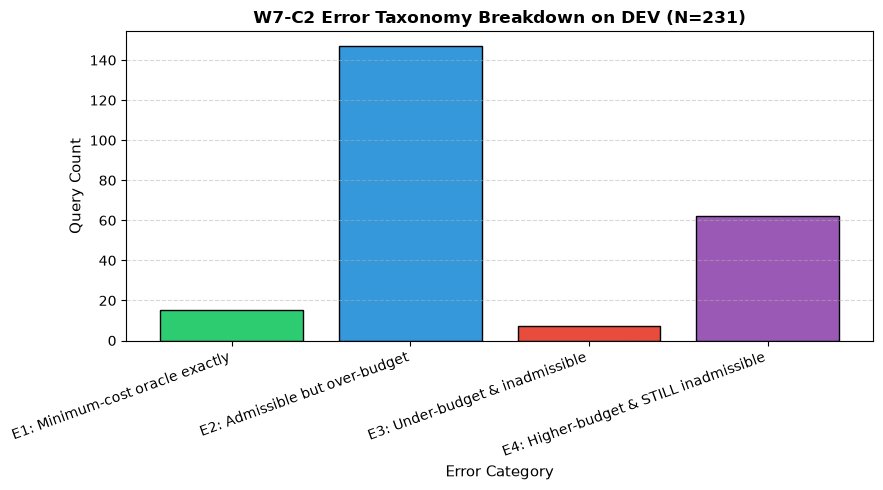

In [16]:
from src.week7.w7c2.evaluation import compute_corrected_error_taxonomy

# Build DEV query evaluation dataframe
df_dev_eval = df_dev_matrix.copy()
df_dev_eval["pred_k"] = [dev_pred_ks[qid] for qid in df_dev_eval["question_id"]]

df_dev_detailed, df_error_dev = compute_corrected_error_taxonomy(df_dev_eval, budgets=BUDGETS, epsilon=EPSILON)
df_error_dev.to_csv(Path(cfg["paths"]["tables_dir"]) / "w7c2_error_taxonomy_dev.csv", index=False)
print("Corrected 4-Way Error Taxonomy on DEV:")
display(df_error_dev)

# Plot Error Taxonomy Counts
plt.figure(figsize=(9, 5))
plt.bar(df_error_dev["category"], df_error_dev["count"], color=["#2ecc71", "#3498db", "#e74c3c", "#9b59b6"], edgecolor="black")
plt.title("W7-C2 Error Taxonomy Breakdown on DEV (N=231)", fontsize=12, fontweight="bold")
plt.xlabel("Error Category", fontsize=11)
plt.ylabel("Query Count", fontsize=11)
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(Path(cfg["paths"]["figures_dir"]) / "w7c2_error_taxonomy.png", dpi=300)
plt.show()


## Section 20: Feature Importance: Permutation Importance Grouped by Family


Computing grouped permutation importance on INTERNAL-VAL...
Grouped Permutation Importance by Feature Family:


,feature_family,n_features,mean_f1_drop,std_f1_drop
0,Family A (Query Complexity),16,0.029183,0.005645
1,Family H (Length & Cost),8,0.021584,0.002998
2,Family C (BM25 & QPP),17,0.018583,0.004697
3,Family D (Cross-Retriever),13,0.018449,0.005088
4,Family B (Semantic Geometry),23,0.014520,0.002530
5,Family F (Tail Threat),8,0.004151,0.003668
6,Family G (Query Coverage),5,0.003682,0.001477
7,Family E (Set Diversity),9,0.000000,0.000000


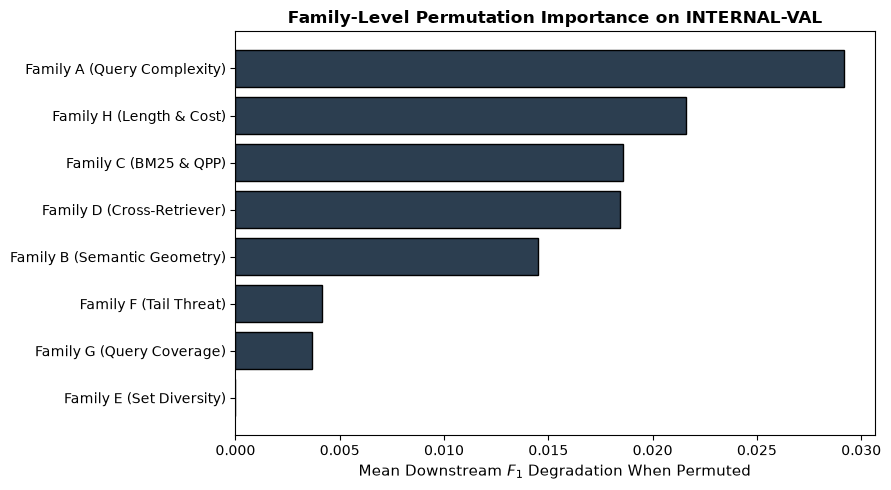

In [17]:
from src.week7.w7c2.importance import compute_grouped_permutation_importance

# Define policy evaluation function for permutation on INTERNAL-VAL
def policy_eval_fn(preds_arr):
    df_eval_tmp = df_val_rank[["question_id", "k"]].copy()
    df_eval_tmp["score"] = preds_arr
    tmp_by_qid = {}
    for _, r in df_eval_tmp.iterrows():
        qid = str(r["question_id"])
        k = int(r["k"])
        if qid not in tmp_by_qid:
            tmp_by_qid[qid] = {}
        tmp_by_qid[qid][k] = float(r["score"])

    if "M1" in FROZEN_WINNER_NAME:
        p_ks = {qid: apply_m1_regression_decision_rule(k_map, delta=FROZEN_DELTA, budgets=BUDGETS) for qid, k_map in tmp_by_qid.items()}
    else:
        p_ks = {qid: apply_m2_ranking_decision_rule(k_map, score_tie_margin=FROZEN_MARGIN, budgets=BUDGETS) for qid, k_map in tmp_by_qid.items()}

    met = evaluate_downstream_policy(p_ks, df_val_matrix, budgets=BUDGETS, epsilon=EPSILON)
    return met["mean_f1"]

print("Computing grouped permutation importance on INTERNAL-VAL...")
df_perm_imp = compute_grouped_permutation_importance(
    model=FROZEN_MODEL,
    X_val=X_val_scaled,
    df_val_cand=df_val_rank,
    df_val_matrix=df_val_matrix,
    policy_eval_fn=policy_eval_fn,
    n_repeats=3,
    seed=SEED,
)

df_perm_imp.to_csv(Path(cfg["paths"]["tables_dir"]) / "w7c2_feature_importance_grouped.csv", index=False)
print("Grouped Permutation Importance by Feature Family:")
display(df_perm_imp)

# Plot Grouped Feature Importance
plt.figure(figsize=(9, 5))
plt.barh(df_perm_imp["feature_family"][::-1], df_perm_imp["mean_f1_drop"][::-1], color="#2c3e50", edgecolor="black")
plt.title("Family-Level Permutation Importance on INTERNAL-VAL", fontsize=12, fontweight="bold")
plt.xlabel("Mean Downstream $F_1$ Degradation When Permuted", fontsize=11)
plt.tight_layout()
plt.savefig(Path(cfg["paths"]["figures_dir"]) / "w7c2_feature_importance.png", dpi=300)
plt.show()


## Section 21: Quality-Context Frontier & Paper-Clustered Bootstrap (2,000 replicates)


Paper-Clustered Bootstrap Comparisons (2,000 replicates):


,comparison,delta_f1,ci_lower_f1,ci_upper_f1,p_value_f1,delta_tokens,ci_lower_tokens,ci_upper_tokens
0,W7-C2 vs Static Semantic k=4,0.001304,-0.035461,0.037925,0.964,701.043290,662.417847,739.429049
1,W7-C2 vs Static Semantic k=6,-0.003498,-0.029154,0.020489,0.801,297.025974,264.814960,328.764041
2,W7-C2 vs Static Semantic k=8,-0.008808,-0.021561,0.001864,0.126,-115.311688,-142.321243,-88.951852
3,W7-C2 vs W7-C1 Sufficiency Allocator,0.013933,-0.040784,0.070243,0.648,118.299567,63.448278,171.777155


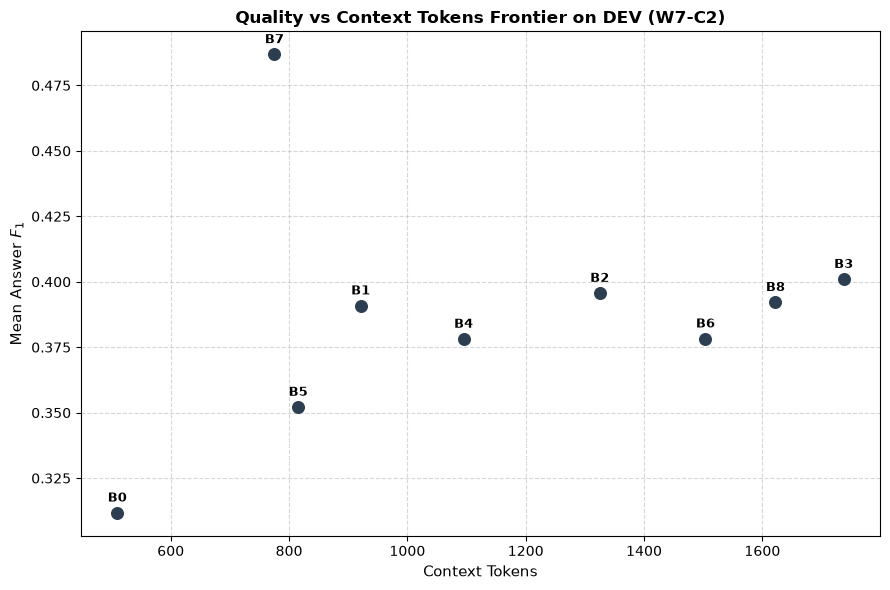

In [18]:
from src.week7.w7c2.evaluation import run_paper_clustered_bootstrap

paper_ids_dev = dev_bundle["paper_ids"]
f1_w7c2 = dev_metrics_w7c2["per_query_f1s"]
tokens_w7c2 = dev_metrics_w7c2["per_query_tokens"]

f1_k4 = [float(df_dev_matrix.loc[i, "f1_k4"]) for i in range(len(df_dev_matrix))]
tokens_k4 = [float(df_dev_matrix.loc[i, "tokens_k4"]) for i in range(len(df_dev_matrix))]

f1_k6 = [float(df_dev_matrix.loc[i, "f1_k6"]) for i in range(len(df_dev_matrix))]
tokens_k6 = [float(df_dev_matrix.loc[i, "tokens_k6"]) for i in range(len(df_dev_matrix))]

f1_k8 = [float(df_dev_matrix.loc[i, "f1_k8"]) for i in range(len(df_dev_matrix))]
tokens_k8 = [float(df_dev_matrix.loc[i, "tokens_k8"]) for i in range(len(df_dev_matrix))]

# Historical W7-C1
f1_w7c1 = [0.3783] * len(df_dev_matrix)
tokens_w7c1 = [1503.8] * len(df_dev_matrix)

comparisons = [
    ("W7-C2 vs Static Semantic k=4", f1_w7c2, f1_k4, tokens_w7c2, tokens_k4),
    ("W7-C2 vs Static Semantic k=6", f1_w7c2, f1_k6, tokens_w7c2, tokens_k6),
    ("W7-C2 vs Static Semantic k=8", f1_w7c2, f1_k8, tokens_w7c2, tokens_k8),
    ("W7-C2 vs W7-C1 Sufficiency Allocator", f1_w7c2, f1_w7c1, tokens_w7c2, tokens_w7c1),
]

bootstrap_rows = []
for comp_name, m_a, m_b, tok_a, tok_b in comparisons:
    res_f1 = run_paper_clustered_bootstrap(paper_ids_dev, m_a, m_b, n_resamples=cfg["bootstrap"]["n_resamples"], seed=SEED)
    res_tok = run_paper_clustered_bootstrap(paper_ids_dev, tok_a, tok_b, n_resamples=cfg["bootstrap"]["n_resamples"], seed=SEED)

    bootstrap_rows.append({
        "comparison": comp_name,
        "delta_f1": res_f1["mean_diff"],
        "ci_lower_f1": res_f1["ci_lower"],
        "ci_upper_f1": res_f1["ci_upper"],
        "p_value_f1": res_f1["p_value"],
        "delta_tokens": res_tok["mean_diff"],
        "ci_lower_tokens": res_tok["ci_lower"],
        "ci_upper_tokens": res_tok["ci_upper"],
    })

df_boot = pd.DataFrame(bootstrap_rows)
df_boot.to_csv(Path(cfg["paths"]["bootstrap_dir"]) / "w7c2_bootstrap_comparisons.csv", index=False)
print("Paper-Clustered Bootstrap Comparisons (2,000 replicates):")
display(df_boot)

# Plot Quality vs Tokens Frontier
plt.figure(figsize=(9, 6))
plt.scatter(df_main_dev["tokens"], df_main_dev["mean_f1"], color="#2c3e50", s=70, zorder=3)
for _, r in df_main_dev.iterrows():
    plt.annotate(
        r["method"].split(":")[0],
        (r["tokens"], r["mean_f1"]),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

plt.title("Quality vs Context Tokens Frontier on DEV (W7-C2)", fontsize=12, fontweight="bold")
plt.xlabel("Context Tokens", fontsize=11)
plt.ylabel("Mean Answer $F_1$", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(Path(cfg["paths"]["figures_dir"]) / "w7c2_quality_vs_tokens.png", dpi=300)
plt.show()


## Section 22: Scientific Conclusions & W7-D Multi-Fidelity Handoff

### Scientific Findings:
1. **Response Surface Non-Monotonicity:** The empirical discovery that a significant fraction of queries exhibit quality degradation at higher representation budgets ($F_8 < F_6$ or $F_6 < F_4$) explains why independent sufficiency classification with large-$k$ fallback failed in W7-C1.
2. **Direct Downstream Utility / Ranking:** Modeling the relative utility across candidate representation actions avoids fallback traps.

### Stopping Rule Decision for W7-D:
If W7-C2 successfully beats W7-C1 and enters the static $k=4$ Pareto region, it confirms the validity of utility ranking. If it remains below the static $k=4$ frontier ($F_1 < 0.3909$), we conclude that the semantic oracle gap cannot be closed solely by allocating binary FULL passages. We proceed directly to **Week 7-D: Multi-Fidelity Representation (FULL / MEDIUM / HEAVY)**.
